# MLP_JK_09 — Clean gene baseline: new reference numbers on V_clean

**Why this notebook:** our standard 50 genes (top 50 by variance) included 2–4 `__ambiguous[...]` read bins per fold. They are not genes (reads that could belong to more than one gene). From now on the standard list is the cleaned one, **V_clean**, and this notebook reruns the baselines and models on it to get the **reference numbers for all later experiments**.

**V_clean**, per outer fold, on training patients only:
1. drop the 299 `__ambiguous[...]` entries of `genes.txt`;
2. keep genes with count > 0 in at least 10% of training spots;
3. take the top 50 by RAW (log1p) variance on training spots.

It must equal MLP_JK_08's V in every fold (checked). The rule is saved to `results/standard_gene_rule.json` for later notebooks.

**Everything else is the same as MLP_JK_03:** RAW target, the same 4 outer patient folds and 4 inner validation groups, embeddings, PCA 256, neighborhoods, MLP settings, shrinkage, ridge.

**Models:** mean predictor, ridge ("ridge raw", center PCA 256), MLP **A** (center only), **D** (center + 3×3 average), **E** (center + 5×5 average, the current Best). Plus the oracle from MLP_JK_06 (D with each test slide's true mean; uses test labels, not a model).

**Old vs. new:** each model's scores on the old list (from MLP_JK_03, and MLP_JK_07 for the level/pattern split) are shown next to V_clean. **The gene lists differ, so a difference is not a model improvement.**

**Best model:** `best_check.csv` reports which model would be Best on V_clean; this notebook does **not** change MLP_JK_Best.

**Reads** `~/JHU/BDD/datasets/BDD_HEST` (read only), `~/JHU/BDD/MLP_JK/results/` (gene_symbols.csv, MLP_JK_03, MLP_JK_07, MLP_JK_08, MLP_JK_Best).
**Saves** to `~/JHU/BDD/MLP_JK/results/MLP_JK_09/`, `~/JHU/BDD/MLP_JK/results/standard_gene_rule.json`, and adds rows to `~/JHU/BDD/MLP_JK/results/all_results.csv`.

In [1]:
import os
import copy
import json
import time
import datetime
import numpy as np
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.neighbors import NearestNeighbors

## Settings

**Paths**
- `SYMBOLS_FILE`: the HGNC gene symbols (from MLP_JK_08).
- `OLD_DIR`: MLP_JK_03's scores on the old list. `OLD_SPLIT_DIR`: MLP_JK_07, whose run 1 has the level/pattern split on the old list.
- `POOL_DIR`: MLP_JK_08's scores, to check that V_clean equals its V.
- `BEST_DIR`: the current MLP_JK_Best (information only).
- `RULE_FILE`: where the standard gene rule is written. `LOG_RESULTS`: whether rows are added to `all_results.csv` (and the rule file is written).

**Gene rule:** `EXCLUDE_PREFIX`, `MIN_DETECTION`, `N_GENES`.

**Evaluation, inputs and MLP:** the same as MLP_JK_03.

In [2]:
DATA_DIR = os.path.expanduser("~/JHU/BDD/datasets/BDD_HEST")
MLP_DIR = os.path.expanduser("~/JHU/BDD/MLP_JK")
RESULTS_DIR = os.path.join(MLP_DIR, "results")
SYMBOLS_FILE = os.path.join(RESULTS_DIR, "gene_symbols.csv")
OLD_DIR = os.path.join(RESULTS_DIR, "MLP_JK_03")
OLD_SPLIT_DIR = os.path.join(RESULTS_DIR, "MLP_JK_07")
POOL_DIR = os.path.join(RESULTS_DIR, "MLP_JK_08")
BEST_DIR = os.path.join(RESULTS_DIR, "MLP_JK_Best")
NOTEBOOK_NAME = "MLP_JK_09"
LOG_RESULTS = True
OUT_DIR = os.path.join(RESULTS_DIR, NOTEBOOK_NAME)
RULE_FILE = os.path.join(RESULTS_DIR, "standard_gene_rule.json")
RESULTS_LOG = os.path.join(RESULTS_DIR, "all_results.csv")

N_FOLDS = 4
N_INNER_FOLDS = 3
ALPHAS = np.logspace(-2, 7, 40)
MIN_TEST_SD = 0.05
SEED = 0

EXCLUDE_PREFIX = "__"
MIN_DETECTION = 0.10
N_GENES = 50

NEIGHBOR_DISTANCE = {"3x3": 1.8, "5x5": 3.0}
N_PCS = 256

HIDDEN_SIZE = 128
DROPOUT = 0.3
WEIGHT_DECAY = 1e-3
LEARNING_RATE = 3e-4
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 10
SHRINK_FACTORS = [0.2, 0.4, 0.6, 0.8, 1.0]
N_VAL_GROUPS = 4
N_FINAL_SEEDS = 3

Names of the models, the device (Apple GPU `mps` if available, otherwise CPU), and fixed seeds. The model names are the same as in MLP_JK_03, so old and new rows line up. The Apple GPU isn't perfectly deterministic, so a rerun can differ in the third decimal.

In [3]:
MODEL_NAMES = {
    "mean": "mean predictor",
    "ridge": "ridge raw",
    "A": "A center only",
    "D": "D 3x3 average",
    "E": "E 5x5 average",
    "O": "O ORACLE (uses test labels)",
}
MLP_SETUPS = {"A": None, "D": "mean_3x3", "E": "mean_5x5"}
GENE_LIST = "V_clean"

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

np.random.seed(SEED)
torch.manual_seed(SEED)

EXPRESSION_DIR = os.path.join(DATA_DIR, "expression")
EMBEDDING_DIR = os.path.join(DATA_DIR, "embeddings")
os.makedirs(OUT_DIR, exist_ok=True)


def save_figure(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")

Device: mps


## Step 1. Load embeddings and expression (copied from Notebook 5)

Each section's embedding file must list the same barcodes, in the same order, as the spot table, and each expression matrix must have one row per spot and one column per gene. The `assert` lines stop the notebook if not.

In [4]:
spot_table = pd.read_csv(os.path.join(DATA_DIR, "spot_table.csv"))
with open(os.path.join(DATA_DIR, "genes.txt")) as f:
    all_genes = np.array(f.read().split())

X_parts = []
Y_parts = []
spot_parts = []

for sample_id in spot_table["sample_id"].unique():
    section_spots = spot_table[spot_table["sample_id"] == sample_id].sort_values("row_in_sample")

    saved = np.load(os.path.join(EMBEDDING_DIR, f"{sample_id}.npz"), allow_pickle=True)
    assert np.array_equal(saved["barcode"], section_spots["barcode"].to_numpy()), \
        f"{sample_id}: embedding rows don't match the spot table"

    expression = scipy.sparse.load_npz(os.path.join(EXPRESSION_DIR, f"{sample_id}.npz"))
    assert expression.shape == (len(section_spots), len(all_genes)), \
        f"{sample_id}: expression shape doesn't match the spot table and genes.txt"

    X_parts.append(saved["embeddings"].astype(np.float32))
    Y_parts.append(expression)
    spot_parts.append(section_spots)

X_raw = np.concatenate(X_parts, axis=0)
Y = scipy.sparse.vstack(Y_parts).tocsc()
spots = pd.concat(spot_parts, ignore_index=True)
del X_parts, Y_parts
patient_array = spots["patient"].to_numpy()
section_array = spots["sample_id"].to_numpy()

print("X (embeddings):", X_raw.shape)
print("Y (log1p expression):", Y.shape)
print("Sections:", spots["sample_id"].nunique(), " Patients:", spots["patient"].nunique())

section_ids = np.unique(section_array)
section_number = np.searchsorted(section_ids, section_array)

X (embeddings): (30600, 4608)
Y (log1p expression): (30600, 11787)
Sections: 68  Patients: 23


## Step 2. Neighborhoods and patient folds (copied from MLP_JK_03)

Neighborhoods: every spot on the same section within 1.8 (3×3) or 3.0 (5×5) spot spacings, including the spot itself. Folds: `GroupKFold` by patient, the same 4 folds as always.

In [5]:
def find_neighborhoods(max_distance):
    neighborhoods = [None] * len(spots)
    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)
        for i, nearby in enumerate(nearby_lists):
            neighborhoods[rows[i]] = rows[nearby]
    return neighborhoods


def neighbor_mean(X, neighborhoods):
    X_smoothed = np.zeros_like(X)
    for i, nearby in enumerate(neighborhoods):
        X_smoothed[i] = X[nearby].mean(axis=0)
    return X_smoothed


neighborhoods = {}
for name, distance in NEIGHBOR_DISTANCE.items():
    neighborhoods[name] = find_neighborhoods(distance)
    sizes = np.array([len(n) for n in neighborhoods[name]])
    full = 9 if name == "3x3" else 25
    print(f"{name}: spots per neighborhood (incl. itself) mean {sizes.mean():.2f}, "
          f"min {sizes.min()}, max {sizes.max()} | full ({full}): {np.mean(sizes == full):.1%}")

3x3: spots per neighborhood (incl. itself) mean 8.30, min 1, max 10 | full (9): 70.7%
5x5: spots per neighborhood (incl. itself) mean 21.25, min 2, max 27 | full (25): 18.2%


In [6]:
fold_of_spot = np.zeros(len(spots), dtype=int)
splitter = GroupKFold(n_splits=N_FOLDS)
for fold, (train_index, test_index) in enumerate(splitter.split(X_raw, groups=patient_array)):
    fold_of_spot[test_index] = fold

for fold in range(N_FOLDS):
    print(f"fold {fold}: {np.sum(fold_of_spot == fold)} test spots | {sorted(np.unique(patient_array[fold_of_spot == fold]))}")

fold_train_index = [np.where(fold_of_spot != fold)[0] for fold in range(N_FOLDS)]
fold_test_index = [np.where(fold_of_spot == fold)[0] for fold in range(N_FOLDS)]

fold 0: 7625 test spots | ['BC23209', 'BC23803', 'BC23810', 'BC23895', 'BC23901', 'BC23903']
fold 1: 7950 test spots | ['BC23268', 'BC23287', 'BC23377', 'BC23450', 'BC23506', 'BC24220']
fold 2: 7876 test spots | ['BC23269', 'BC23270', 'BC23277', 'BC23508', 'BC23567', 'BC24105']
fold 3: 7149 test spots | ['BC23272', 'BC23288', 'BC23944', 'BC24044', 'BC24223']


## Step 3. The standard gene list, V_clean

**`standard_genes(train_index)`** applies the rule on the given training spots: drop the `__ambiguous` bins, keep genes with count > 0 in at least 10% of the spots, and return the top 50 by variance (most variable first). It is the same calculation as Notebook 5's `choose_genes`, with the two filters added.

Checks and reports:
- V_clean must equal MLP_JK_08's V (its pool's top 50) in every fold, or the notebook stops.
- Per fold: overlap with the old list (MLP_JK_03), and which genes enter and leave.
- `standard_genes.csv`: the lists with symbols. `standard_gene_rule.json`: the rule, for later notebooks.

In [7]:
symbols = pd.read_csv(SYMBOLS_FILE)
symbol_of = dict(zip(symbols["ensembl_id"], symbols["symbol"]))
is_excluded = np.char.startswith(all_genes.astype(str), EXCLUDE_PREFIX)
print(f"genes.txt: {len(all_genes)} entries, {is_excluded.sum()} excluded ({EXCLUDE_PREFIX}... bins)")


def standard_genes(train_index):
    Y_train = Y[train_index]
    detection = np.asarray((Y_train > 0).mean(axis=0)).ravel()
    mean = np.asarray(Y_train.mean(axis=0)).ravel()
    variance = np.asarray(Y_train.multiply(Y_train).mean(axis=0)).ravel() - mean ** 2
    candidates = np.where(~is_excluded & (detection >= MIN_DETECTION))[0]
    chosen = candidates[np.argsort(variance[candidates])[::-1][:N_GENES]]
    return chosen, detection, variance


fold_genes = []
gene_rows = []
for fold in range(N_FOLDS):
    chosen, detection, variance = standard_genes(fold_train_index[fold])
    fold_genes.append(chosen)
    for rank, g in enumerate(chosen):
        gene_rows.append({"fold": fold, "rank": rank, "ensembl_id": all_genes[g], "symbol": symbol_of[all_genes[g]],
                          "detection": detection[g], "train_variance": variance[g]})
standard_gene_table = pd.DataFrame(gene_rows)

pool_scores = pd.read_csv(os.path.join(POOL_DIR, "gene_scores.csv"))
for fold in range(N_FOLDS):
    pool_v = set(pool_scores.loc[(pool_scores["fold"] == fold) & pool_scores["in_V"], "ensembl_id"])
    assert pool_v == set(all_genes[fold_genes[fold]]), f"fold {fold}: V_clean differs from MLP_JK_08's V"
print("V_clean equals MLP_JK_08's V in every fold.\n")

old_pooled = pd.read_csv(os.path.join(OLD_DIR, "pooled_gene_scores.csv"))
old_genes = old_pooled[old_pooled["model"] == "E 5x5 average"]


def name(gene):
    return symbol_of.get(gene, gene)


overlap_rows = []
for fold in range(N_FOLDS):
    old_set = set(old_genes.loc[old_genes["fold"] == fold, "gene"])
    new_set = set(all_genes[fold_genes[fold]])
    overlap_rows.append({
        "fold": fold,
        "overlap": len(old_set & new_set),
        "entered": ", ".join(sorted(name(g) for g in new_set - old_set)),
        "left": ", ".join(sorted(name(g) for g in old_set - new_set)),
    })
gene_list_changes = pd.DataFrame(overlap_rows)
for _, row in gene_list_changes.iterrows():
    print(f"fold {row['fold']}: {row['overlap']} of 50 genes kept\n  entered: {row['entered']}\n  left:    {row['left']}")

standard_gene_rule = {
    "name": GENE_LIST,
    "description": "Standard gene list: top 50 genes by variance of log1p counts, after removing "
                   "__ambiguous bins and rarely expressed genes. Computed per outer fold on training patients only.",
    "exclude_prefix": EXCLUDE_PREFIX,
    "min_detection": MIN_DETECTION,
    "detection_means": "fraction of training spots with count > 0",
    "n_genes": N_GENES,
    "rank_by": "variance of log1p(count) across training spots (highest first)",
    "computed_on": "training patients of each outer fold (GroupKFold by patient, 4 folds)",
    "gene_symbols": SYMBOLS_FILE,
    "defined_in": "MLP_JK_09_clean_gene_baseline.ipynb",
}
standard_gene_table.to_csv(os.path.join(OUT_DIR, "standard_genes.csv"), index=False)
gene_list_changes.to_csv(os.path.join(OUT_DIR, "gene_list_changes.csv"), index=False)
if LOG_RESULTS:
    with open(RULE_FILE, "w") as f:
        json.dump(standard_gene_rule, f, indent=2)

genes.txt: 11787 entries, 299 excluded (__... bins)


V_clean equals MLP_JK_08's V in every fold.

fold 0: 48 of 50 genes kept
  entered: EEF2, RPL8
  left:    __ambiguous[ENSG00000257341+ENSG00000213145], __ambiguous[ENSG00000273259+ENSG00000196136]
fold 1: 46 of 50 genes kept
  entered: CTSD, LY6E, P4HB, RPL18
  left:    __ambiguous[ENSG00000185885+ENSG00000185201], __ambiguous[ENSG00000243678+ENSG00000011052], __ambiguous[ENSG00000257341+ENSG00000213145], __ambiguous[ENSG00000273259+ENSG00000196136]
fold 2: 46 of 50 genes kept
  entered: ACTG1, FN1, RPS4X, XBP1
  left:    __ambiguous[ENSG00000185885+ENSG00000185201], __ambiguous[ENSG00000243678+ENSG00000011052], __ambiguous[ENSG00000257341+ENSG00000213145], __ambiguous[ENSG00000273259+ENSG00000196136]
fold 3: 47 of 50 genes kept
  entered: HLA-B, IGFBP2, RPL31
  left:    __ambiguous[ENSG00000243678+ENSG00000011052], __ambiguous[ENSG00000257341+ENSG00000213145], __ambiguous[ENSG00000273259+ENSG00000196136]


## Step 4. Scoring and the error split

**`score_model`** (copied from Notebook 5): per gene, pooled PCC and NRMSE (genes with test SD < 0.05 get no NRMSE), and the same within each test patient.

**`error_parts`** (from MLP_JK_06/07): a fold's MSE split into **level error** (each test slide's predicted mean vs. its true mean) and **pattern error** (what's left inside each slide), over the genes that also get an NRMSE. It checks that the two add up to the MSE.

**`replace_levels`**: the oracle. Each test slide's predicted mean is replaced by its true mean.

In [8]:
def pcc(a, b):
    if np.std(a) < 1e-6 or np.std(b) < 1e-6:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def score_model(model_name, fold_results, prediction_key):
    pooled_rows = []
    within_rows = []
    for r in fold_results:
        y_true = r["y_test"]
        y_pred = r[prediction_key]
        test_patients = patient_array[r["test_index"]]

        for g, gene in enumerate(r["genes"]):
            sd = np.std(y_true[:, g])
            rmse = np.sqrt(np.mean((y_true[:, g] - y_pred[:, g]) ** 2))
            pooled_rows.append({
                "model": model_name, "fold": r["fold"], "gene": gene,
                "PCC": pcc(y_true[:, g], y_pred[:, g]),
                "NRMSE": rmse / sd if sd >= MIN_TEST_SD else np.nan,
                "alpha": r["alpha"][g] if prediction_key == "y_pred" else np.nan,
            })

        for patient in np.unique(test_patients):
            rows = test_patients == patient
            for g, gene in enumerate(r["genes"]):
                t = y_true[rows, g]
                p = y_pred[rows, g]
                sd = np.std(t)
                if sd < MIN_TEST_SD:
                    continue
                centered_mse = np.mean(((t - t.mean()) - (p - p.mean())) ** 2)
                within_rows.append({
                    "model": model_name, "fold": r["fold"], "patient": patient, "gene": gene,
                    "PCC_within": pcc(t, p),
                    "NRMSE_within": np.sqrt(np.mean((t - p) ** 2)) / sd,
                    "NRMSE_centered": np.sqrt(centered_mse) / sd,
                })
    return pd.DataFrame(pooled_rows), pd.DataFrame(within_rows)


def split_error(y_true, y_pred, rows):
    sections = section_number[rows]
    level_error = np.zeros(y_true.shape[1])
    pattern_error = np.zeros(y_true.shape[1])
    for s in np.unique(sections):
        in_section = sections == s
        error = y_true[in_section] - y_pred[in_section]
        share = in_section.mean()
        level_error += share * error.mean(axis=0) ** 2
        pattern_error += share * error.var(axis=0)
    return level_error.mean(), pattern_error.mean()


def error_parts(result):
    scored = result["y_test"].std(axis=0) >= MIN_TEST_SD
    y_true = result["y_test"][:, scored]
    y_pred = result["y_pred"][:, scored]
    mse = np.mean((y_true - y_pred) ** 2)
    level_error, pattern_error = split_error(y_true, y_pred, result["test_index"])
    assert abs(level_error + pattern_error - mse) < 1e-6, "level + pattern doesn't add up to the MSE"
    return mse, level_error, pattern_error, scored.sum()


def replace_levels(prediction, rows, y_true):
    new_prediction = prediction.copy()
    sections = section_number[rows]
    for s in np.unique(sections):
        in_section = sections == s
        new_prediction[in_section] = (prediction[in_section] - prediction[in_section].mean(axis=0)
                                      + y_true[in_section].mean(axis=0))
    return new_prediction

## Step 5. PCA inputs for every fold (as in MLP_JK_03)

On each fold's training spots: StandardScaler + PCA 256 of the center embeddings, the 3×3 averages and the 5×5 averages. A = `center`; D = `center` + `mean_3x3`; E = `center` + `mean_5x5`. Ridge uses `center` (Notebook 5's "ridge raw" input).

In [9]:
def pca_256(X, train_index):
    scaler = StandardScaler()
    pca = PCA(n_components=N_PCS, random_state=SEED)
    pca.fit(scaler.fit_transform(X[train_index]))
    return pca.transform(scaler.transform(X)).astype(np.float32)


start_time = time.time()
X_mean_3x3 = neighbor_mean(X_raw, neighborhoods["3x3"])
X_mean_5x5 = neighbor_mean(X_raw, neighborhoods["5x5"])
fold_inputs = []
for fold in range(N_FOLDS):
    train_index = fold_train_index[fold]
    fold_inputs.append({
        "center": pca_256(X_raw, train_index),
        "mean_3x3": pca_256(X_mean_3x3, train_index),
        "mean_5x5": pca_256(X_mean_5x5, train_index),
    })
    print(f"fold {fold}: PCA inputs done ({(time.time() - start_time) / 60:.1f} min)", flush=True)
del X_raw, X_mean_3x3, X_mean_5x5

fold 0: PCA inputs done (0.2 min)


fold 1: PCA inputs done (0.4 min)


fold 2: PCA inputs done (0.6 min)


fold 3: PCA inputs done (0.8 min)


## Step 6. Ridge, the MLP, and shrinkage (copied from Notebook 5 and MLP_JK_03)

**Ridge:** one alpha per gene, chosen by 3-fold patient-grouped cross-validation inside the training patients.

**The MLP:** input → Linear(input, 128) → ReLU → Dropout 0.3 → Linear(128, 50). Adam (weight decay 1e-3), MSE loss on standardized genes, batches of 256, early stopping with patience 10 on validation patients. `shrink` = `train_mean + k × (prediction − train_mean)`.

In [10]:
def choose_alpha_per_gene(P_train, y_train, inner_groups):
    n_inner = min(N_INNER_FOLDS, len(np.unique(inner_groups)))
    inner_splits = GroupKFold(n_splits=n_inner).split(P_train, groups=inner_groups)

    errors = np.zeros((len(ALPHAS), y_train.shape[1]))
    for inner_train, inner_val in inner_splits:
        for a, alpha in enumerate(ALPHAS):
            model = Ridge(alpha=alpha)
            model.fit(P_train[inner_train], y_train[inner_train])
            prediction = model.predict(P_train[inner_val])
            errors[a] += np.mean((prediction - y_train[inner_val]) ** 2, axis=0)

    best = np.argmin(errors, axis=0)
    return ALPHAS[best]


def fit_and_predict(P_train, y_train, P_test, alpha_per_gene):
    y_pred = np.zeros((P_test.shape[0], y_train.shape[1]))
    for alpha in np.unique(alpha_per_gene):
        genes_with_this_alpha = np.where(alpha_per_gene == alpha)[0]
        model = Ridge(alpha=alpha)
        model.fit(P_train, y_train[:, genes_with_this_alpha])
        y_pred[:, genes_with_this_alpha] = model.predict(P_test).reshape(len(P_test), -1)
    return y_pred

In [11]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(n_hidden, n_outputs),
        )

    def forward(self, x):
        return self.layers(x)


def to_device(array):
    return torch.tensor(np.asarray(array), dtype=torch.float32, device=device)


def predict(trained, P_device, rows):
    model = trained["model"]
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(rows), 4096):
            batch_rows = torch.tensor(rows[start:start + 4096], device=device)
            outputs.append(model(P_device[batch_rows]).cpu().numpy())
    y_scaled = np.concatenate(outputs, axis=0)
    return y_scaled * trained["gene_sd"] + trained["gene_mean"]


def shrink(y_pred, train_mean, k):
    return train_mean + k * (y_pred - train_mean)


def train_mlp(P_device, y_fold, train_rows, val_rows, n_epochs, seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    gene_mean = y_fold[train_rows].mean(axis=0)
    gene_sd = y_fold[train_rows].std(axis=0)
    y_scaled = to_device((y_fold - gene_mean) / gene_sd)

    model = MLP(P_device.shape[1], HIDDEN_SIZE, N_GENES, DROPOUT).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_function = nn.MSELoss()

    trained = {
        "model": model,
        "gene_mean": gene_mean,
        "gene_sd": gene_sd,
        "history": [],
        "best_epoch": n_epochs,
    }

    best_val_loss = np.inf
    best_weights = None
    for epoch in range(1, n_epochs + 1):
        model.train()
        shuffled = rng.permutation(train_rows)
        batch_losses = []
        for start in range(0, len(shuffled), BATCH_SIZE):
            batch_rows = torch.tensor(shuffled[start:start + BATCH_SIZE], device=device)
            loss = loss_function(model(P_device[batch_rows]), y_scaled[batch_rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = np.mean(batch_losses)

        if val_rows is None:
            trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": np.nan})
            continue

        val_pred = predict(trained, P_device, val_rows)
        val_loss = np.mean(((val_pred - y_fold[val_rows]) / gene_sd) ** 2)
        trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            trained["best_epoch"] = epoch
            best_weights = copy.deepcopy(model.state_dict())
        elif epoch - trained["best_epoch"] >= PATIENCE:
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return trained

## Step 7. One fold, start to finish (as in MLP_JK_03)

| Step | Uses |
|---|---|
| V_clean, gene means and SDs, ridge alphas | training patients |
| For each of the 4 validation groups | A, D and E trained on the fit patients, early stopping on the validation patients |
| `k` | lowest validation NRMSE averaged over the 4 groups, per setup |
| Epochs | median best epoch over the 4 groups |
| Final models | A, D and E on **all** training patients, 3 seeds each, averaged |
| Test patients | used once, for scoring. The oracle also uses the true test slide means, and is labeled as such |

The test spots' expression is `NaN` in every array the training reads.

In [12]:
def validation_groups(train_index):
    groups = patient_array[train_index]
    splits = []
    for inner_fit, inner_val in GroupKFold(n_splits=N_VAL_GROUPS).split(train_index, groups=groups):
        splits.append((train_index[inner_fit], train_index[inner_val]))
    return splits


def build_input(setup, fold):
    center = fold_inputs[fold]["center"]
    if MLP_SETUPS[setup] is None:
        return center
    return np.concatenate([center, fold_inputs[fold][MLP_SETUPS[setup]]], axis=1)


def run_fold(fold):
    gene_index = fold_genes[fold]
    genes = all_genes[gene_index]
    train_index = fold_train_index[fold]
    test_index = fold_test_index[fold]
    no_alpha = np.full(N_GENES, np.nan)

    y_fold = Y[:, gene_index].toarray()
    y_fold[test_index] = np.nan
    y_test = Y[test_index][:, gene_index].toarray()
    train_mean = y_fold[train_index].mean(axis=0)
    center = fold_inputs[fold]["center"]

    def as_result(prediction, alpha=no_alpha):
        return {"fold": fold, "test_index": test_index, "genes": genes, "y_test": y_test,
                "y_pred": prediction, "alpha": alpha}

    test_results = {"mean": as_result(np.tile(train_mean, (len(test_index), 1)))}
    seed_results = {}

    alpha_per_gene = choose_alpha_per_gene(center[train_index], y_fold[train_index], patient_array[train_index])
    ridge_prediction = fit_and_predict(center[train_index], y_fold[train_index], center[test_index], alpha_per_gene)
    test_results["ridge"] = as_result(ridge_prediction, alpha_per_gene)

    val_rows = []
    chosen_rows = []
    for setup in MLP_SETUPS:
        P_device = to_device(build_input(setup, fold))

        for group, (fit_rows, val_index) in enumerate(validation_groups(train_index)):
            fit_mean = y_fold[fit_rows].mean(axis=0)
            val_result = {
                "fold": fold,
                "test_index": val_index,
                "genes": genes,
                "y_test": y_fold[val_index],
                "y_mean": np.tile(fit_mean, (len(val_index), 1)),
                "alpha": no_alpha,
            }
            mean_scores, _ = score_model("mean predictor", [val_result], "y_mean")

            trained = train_mlp(P_device, y_fold, fit_rows, val_index, MAX_EPOCHS, SEED)
            val_pred = predict(trained, P_device, val_index)
            for k in SHRINK_FACTORS:
                val_result["y_pred"] = shrink(val_pred, fit_mean, k)
                scores, _ = score_model("MLP", [val_result], "y_pred")
                val_rows.append({
                    "setup": setup, "fold": fold, "val_group": group, "k": k,
                    "val_PCC": scores["PCC"].mean(),
                    "val_NRMSE": scores["NRMSE"].mean(),
                    "val_mean_predictor_NRMSE": mean_scores["NRMSE"].mean(),
                    "best_epoch": trained["best_epoch"],
                })

        val_table = pd.DataFrame(val_rows)
        by_k = val_table[val_table["setup"] == setup].groupby("k").agg(
            val_PCC=("val_PCC", "mean"),
            val_NRMSE=("val_NRMSE", "mean"),
            val_mean_predictor_NRMSE=("val_mean_predictor_NRMSE", "mean"),
            epochs=("best_epoch", "median"),
        ).reset_index()
        chosen = by_k.loc[by_k["val_NRMSE"].idxmin()].to_dict()
        chosen["passes"] = chosen["val_NRMSE"] <= chosen["val_mean_predictor_NRMSE"]
        chosen["final_epochs"] = max(1, int(round(chosen["epochs"])))
        chosen.update({"setup": setup, "fold": fold})
        chosen_rows.append(chosen)

        seed_predictions = []
        for seed_number in range(N_FINAL_SEEDS):
            final = train_mlp(P_device, y_fold, train_index, None, chosen["final_epochs"], SEED + seed_number)
            seed_predictions.append(predict(final, P_device, test_index))
        del P_device

        test_results[setup] = as_result(shrink(np.mean(seed_predictions, axis=0), train_mean, chosen["k"]))
        seed_results[setup] = [as_result(shrink(p, train_mean, chosen["k"])) for p in seed_predictions]

    test_results["O"] = as_result(replace_levels(test_results["D"]["y_pred"], test_index, y_test))
    seed_results["O"] = [as_result(replace_levels(r["y_pred"], test_index, y_test)) for r in seed_results["D"]]
    return test_results, seed_results, pd.DataFrame(val_rows), chosen_rows

## Step 8. Run every fold

In [13]:
results = {model: [] for model in MODEL_NAMES}
seed_results = {setup: [[] for _ in range(N_FINAL_SEEDS)] for setup in ["A", "D", "E", "O"]}
val_tables = []
chosen_rows = []
start_time = time.time()

for fold in range(N_FOLDS):
    fold_results, fold_seed_results, val_table, chosen = run_fold(fold)
    for model in MODEL_NAMES:
        results[model].append(fold_results[model])
    for setup, seed_list in fold_seed_results.items():
        for seed_number, seed_result in enumerate(seed_list):
            seed_results[setup][seed_number].append(seed_result)
    val_tables.append(val_table)
    chosen_rows.extend(chosen)
    ks = ", ".join(f"{c['setup']} k = {c['k']}" for c in chosen)
    print(f"fold {fold} done: {ks}  ({(time.time() - start_time) / 60:.1f} min)", flush=True)
    if device.type == "mps":
        torch.mps.empty_cache()

val_scores = pd.concat(val_tables, ignore_index=True)
chosen_settings = pd.DataFrame(chosen_rows)

fold 0 done: A k = 0.4, D k = 0.4, E k = 0.4  (0.6 min)


fold 1 done: A k = 0.4, D k = 0.2, E k = 0.4  (1.0 min)


fold 2 done: A k = 0.4, D k = 0.4, E k = 0.4  (1.6 min)


fold 3 done: A k = 0.4, D k = 0.4, E k = 0.4  (2.0 min)


## Step 9. Results on V_clean

**Chosen `k` and epochs** per setup and fold (validation patients only). `passes` = validation NRMSE no worse than the mean predictor's.

In [14]:
pd.set_option("display.width", 250)
columns = ["setup", "fold", "k", "final_epochs", "val_PCC", "val_NRMSE", "val_mean_predictor_NRMSE", "passes"]
print(chosen_settings.sort_values(["setup", "fold"])[columns].round(4).to_string(index=False))

setup  fold   k  final_epochs  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes
    A     0 0.4            14   0.2252     1.1179                    1.1441    True
    A     1 0.4             8   0.1477     1.1132                    1.1268    True
    A     2 0.4            14   0.1946     1.0697                    1.0978    True
    A     3 0.4             6   0.1984     1.0682                    1.0825    True
    D     0 0.4            14   0.2405     1.1142                    1.1441    True
    D     1 0.2             9   0.1617     1.1123                    1.1268    True
    D     2 0.4            14   0.2081     1.0629                    1.0978    True
    D     3 0.4             6   0.2208     1.0639                    1.0825    True
    E     0 0.4            12   0.2982     1.0978                    1.1441    True
    E     1 0.4            12   0.1907     1.1077                    1.1268    True
    E     2 0.4            18   0.2108     1.0601                    1.0978 

**Scores.** Test MSE, level and pattern error are averaged over all scored genes; PCC, NRMSE and within-patient PCC over all genes (and patients), as in MLP_JK_03. **Seed spread** = the range of each score over the 3 final seeds.

In [15]:
def score_results(fold_results, model_name):
    pooled, within = score_model(model_name, fold_results, "y_pred")
    rows = []
    for r in fold_results:
        mse, level_error, pattern_error, n_scored = error_parts(r)
        fold = r["fold"]
        rows.append({
            "model": model_name, "fold": fold, "MSE": mse, "level_error": level_error,
            "pattern_error": pattern_error, "genes_scored": n_scored,
            "PCC": pooled.loc[pooled["fold"] == fold, "PCC"].mean(),
            "NRMSE": pooled.loc[pooled["fold"] == fold, "NRMSE"].mean(),
            "PCC_within": within.loc[within["fold"] == fold, "PCC_within"].mean(),
        })
    folds = pd.DataFrame(rows)
    folds["level_share"] = folds["level_error"] / folds["MSE"]
    n = folds["genes_scored"]
    overall = {
        "test_MSE": np.sum(folds["MSE"] * n) / n.sum(),
        "pooled_PCC": pooled["PCC"].mean(),
        "within_PCC": within["PCC_within"].mean(),
        "NRMSE": pooled["NRMSE"].mean(),
        "level_error": np.sum(folds["level_error"] * n) / n.sum(),
        "pattern_error": np.sum(folds["pattern_error"] * n) / n.sum(),
    }
    overall["level_share"] = overall["level_error"] / overall["test_MSE"]
    return folds, overall, pooled, within


summary_rows = []
fold_tables = []
pooled_tables = []
within_tables = []
for model, model_name in MODEL_NAMES.items():
    folds, overall, pooled_part, within_part = score_results(results[model], model_name)
    row = {"gene_list": GENE_LIST, "model": model_name}
    row.update(overall)
    if model in MLP_SETUPS:
        c = chosen_settings[chosen_settings["setup"] == model].sort_values("fold")
        row["val_PCC"] = c["val_PCC"].mean()
        row["val_NRMSE"] = c["val_NRMSE"].mean()
        row["val_mean_predictor_NRMSE"] = c["val_mean_predictor_NRMSE"].mean()
        row["chosen_k"] = "/".join(str(k) for k in c["k"])
    if model == "O":
        row["chosen_k"] = "same as D"
    if model in seed_results:
        seed_overall = [score_results(seed_results[model][s], "seed")[1] for s in range(N_FINAL_SEEDS)]
        for metric in ["test_MSE", "pooled_PCC", "within_PCC", "NRMSE"]:
            values = [o[metric] for o in seed_overall]
            row[f"seed_range_{metric}"] = max(values) - min(values)
    summary_rows.append(row)
    fold_tables.append(folds)
    pooled_tables.append(pooled_part)
    within_tables.append(within_part)

summary = pd.DataFrame(summary_rows)
fold_scores = pd.concat(fold_tables, ignore_index=True)
pooled = pd.concat(pooled_tables, ignore_index=True)
within = pd.concat(within_tables, ignore_index=True)
assert np.allclose(summary["level_error"] + summary["pattern_error"], summary["test_MSE"]), "split doesn't add up"
mean_predictor_nrmse = summary.loc[summary["model"] == "mean predictor", "NRMSE"].iloc[0]

summary_columns = ["model", "test_MSE", "pooled_PCC", "within_PCC", "NRMSE", "val_PCC", "val_NRMSE", "chosen_k",
                   "level_error", "pattern_error", "level_share"]
print(summary[summary_columns].round(4).to_string(index=False))
print("\nSeed spread (max - min over the 3 seeds):")
print(summary.dropna(subset=["seed_range_test_MSE"])[["model"] + [c for c in summary.columns if c.startswith("seed_range")]]
      .round(4).to_string(index=False))
print("\nLevel and pattern error add up to the test MSE in every fold, for every model.")

print()
for column, title in [("MSE", "Test MSE"), ("PCC", "Pooled PCC"), ("NRMSE", "NRMSE"), ("PCC_within", "Within-patient PCC")]:
    print(f"{title} per fold:")
    print(fold_scores.pivot(index="model", columns="fold", values=column).reindex(list(MODEL_NAMES.values())).round(4).to_string())
    print()

                      model  test_MSE  pooled_PCC  within_PCC  NRMSE  val_PCC  val_NRMSE        chosen_k  level_error  pattern_error  level_share
             mean predictor    0.9987         NaN         NaN 1.0980      NaN        NaN             NaN       0.5917         0.4070       0.5925
                  ridge raw    0.9674      0.1945      0.1573 1.0863      NaN        NaN             NaN       0.5517         0.4157       0.5703
              A center only    0.9609      0.1835      0.1503 1.0776   0.1915     1.0923 0.4/0.4/0.4/0.4       0.5641         0.3968       0.5870
              D 3x3 average    0.9568      0.2059      0.1626 1.0755   0.2078     1.0883 0.4/0.2/0.4/0.4       0.5631         0.3937       0.5885
              E 5x5 average    0.9451      0.2053      0.1731 1.0673   0.2376     1.0804 0.4/0.4/0.4/0.4       0.5550         0.3901       0.5873
O ORACLE (uses test labels)    0.3937      0.6609      0.2548 0.7230      NaN        NaN       same as D       0.0000       

## Step 10. Old list vs. V_clean

The old numbers come from MLP_JK_03 (same models, settings and seeds, on the old top-50 list), and the old level/pattern split from MLP_JK_07's run 1 (the same old list; A wasn't in it). **The gene lists differ (2–4 genes per fold), so these differences are not model improvements**; they show how much the reference numbers move.

The rankings are printed separately for test MSE (lower is better) and validation PCC (higher is better).

In [16]:
old_summary = pd.read_csv(os.path.join(OLD_DIR, "summary.csv"))
old_split = pd.read_csv(os.path.join(OLD_SPLIT_DIR, "summary.csv"))
old_split = old_split[(old_split["target"] == "raw") & (old_split["gene_set"] == "G_raw")]

old_rows = []
for model_name in MODEL_NAMES.values():
    row = {"gene_list": "old_top50 (MLP_JK_03)", "model": model_name}
    found = old_summary[old_summary["model"] == model_name]
    if len(found):
        for column in ["test_MSE", "pooled_PCC", "within_PCC", "NRMSE", "val_PCC", "val_NRMSE", "chosen_k"]:
            row[column] = found.iloc[0][column]
    split = old_split[old_split["model"] == model_name]
    if len(split):
        for column in ["level_error", "pattern_error", "level_share"]:
            row[column] = split.iloc[0][column]
        if model_name == MODEL_NAMES["O"]:
            for column in ["test_MSE", "pooled_PCC", "within_PCC", "NRMSE"]:
                row[column] = split.iloc[0][column]
    old_rows.append(row)
old_table = pd.DataFrame(old_rows)

compare_columns = ["test_MSE", "pooled_PCC", "within_PCC", "NRMSE", "val_PCC", "val_NRMSE", "level_share"]
old_vs_new = pd.concat([old_table, summary[["gene_list", "model"] + compare_columns + ["chosen_k", "level_error", "pattern_error"]]],
                       ignore_index=True)
old_vs_new["note"] = "gene lists differ (old list had __ambiguous bins); not a model improvement"
order = {name: i for i, name in enumerate(MODEL_NAMES.values())}
old_vs_new = old_vs_new.sort_values(["model", "gene_list"], key=lambda c: c.map(order) if c.name == "model" else c)
print(old_vs_new[["model", "gene_list"] + compare_columns].round(4).to_string(index=False))

old_fold_scores = pd.read_csv(os.path.join(OLD_DIR, "fold_scores.csv"))


def ranking(table, column, models, lower_is_better):
    rows = table[table["model"].isin(models)].sort_values(column, ascending=lower_is_better)
    sign = " < " if lower_is_better else " > "
    return sign.join(f"{m.split(' ')[0] if m != 'mean predictor' else 'mean'} {v:.4f}"
                     for m, v in zip(rows["model"], rows[column]))


real_models = [MODEL_NAMES[m] for m in ["mean", "ridge", "A", "D", "E"]]
mlp_models = [MODEL_NAMES[m] for m in MLP_SETUPS]
rankings = {
    "test MSE (lower is better), old list": ranking(old_table, "test_MSE", real_models, True),
    "test MSE (lower is better), V_clean": ranking(summary, "test_MSE", real_models, True),
    "validation PCC (higher is better), old list": ranking(old_table, "val_PCC", mlp_models, False),
    "validation PCC (higher is better), V_clean": ranking(summary, "val_PCC", mlp_models, False),
}
print()
for title, text in rankings.items():
    print(f"{title}:\n  {text}")

                      model             gene_list  test_MSE  pooled_PCC  within_PCC  NRMSE  val_PCC  val_NRMSE  level_share
             mean predictor               V_clean    0.9987         NaN         NaN 1.0980      NaN        NaN       0.5925
             mean predictor old_top50 (MLP_JK_03)    1.0092         NaN         NaN 1.0997      NaN        NaN       0.6019
                  ridge raw               V_clean    0.9674      0.1945      0.1573 1.0863      NaN        NaN       0.5703
                  ridge raw old_top50 (MLP_JK_03)    0.9837      0.1868      0.1514 1.0917      NaN        NaN       0.5799
              A center only               V_clean    0.9609      0.1835      0.1503 1.0776   0.1915     1.0923       0.5870
              A center only old_top50 (MLP_JK_03)    0.9728      0.1767      0.1433 1.0806   0.1898     1.0923          NaN
              D 3x3 average               V_clean    0.9568      0.2059      0.1626 1.0755   0.2078     1.0883       0.5885
        

## Step 11. Best check on V_clean (report only)

The usual rule among A, D and E: the **highest validation PCC**, with validation NRMSE no worse than the mean predictor's. The current MLP_JK_Best's validation PCC (on the old list) is shown for information only; it isn't comparable. **This notebook does not change MLP_JK_Best.**

In [17]:
best_summary = pd.read_csv(os.path.join(BEST_DIR, "summary.csv"))
best_row = best_summary[best_summary["val_PCC"].notna() & ~best_summary["model"].str.contains("logged")].iloc[0]

best_rows = []
for setup in MLP_SETUPS:
    row = summary[summary["model"] == MODEL_NAMES[setup]].iloc[0]
    best_rows.append({
        "gene_list": GENE_LIST, "model": MODEL_NAMES[setup],
        "val_PCC": row["val_PCC"], "val_NRMSE": row["val_NRMSE"],
        "val_mean_predictor_NRMSE": row["val_mean_predictor_NRMSE"],
        "passes_NRMSE_rule": row["val_NRMSE"] <= row["val_mean_predictor_NRMSE"],
    })
best_check = pd.DataFrame(best_rows)
passing = best_check[best_check["passes_NRMSE_rule"]]
best_check["best_on_V_clean"] = best_check["model"] == passing.loc[passing["val_PCC"].idxmax(), "model"]
best_check["current_Best_val_PCC_old_list"] = best_row["val_PCC"]
best_check["note"] = "report only; MLP_JK_Best not changed. Current Best's val PCC is on the old list"
print(best_check.round(4).to_string(index=False))
print(f"\nBest on V_clean by the rule: {best_check.loc[best_check['best_on_V_clean'], 'model'].iloc[0]}")
print(f"(Current MLP_JK_Best: {best_row['model']}, validation PCC {best_row['val_PCC']:.4f} on the old list.)")

gene_list         model  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes_NRMSE_rule  best_on_V_clean  current_Best_val_PCC_old_list                                                                            note
  V_clean A center only   0.1915     1.0923                    1.1128               True            False                         0.2256 report only; MLP_JK_Best not changed. Current Best's val PCC is on the old list
  V_clean D 3x3 average   0.2078     1.0883                    1.1128               True            False                         0.2256 report only; MLP_JK_Best not changed. Current Best's val PCC is on the old list
  V_clean E 5x5 average   0.2376     1.0804                    1.1128               True             True                         0.2256 report only; MLP_JK_Best not changed. Current Best's val PCC is on the old list

Best on V_clean by the rule: E 5x5 average
(Current MLP_JK_Best: E 5x5 average, validation PCC 0.2256 on the old list.)


## Step 12. Plots

**Figure 1:** test MSE and pooled PCC per model on V_clean. Bars = average over folds, dots = the 4 folds, black line = the range over the 3 seeds; red dashed line = the mean predictor's MSE. The oracle is left out (it uses test labels).

**Figure 2:** within-patient PCC per model, old list (MLP_JK_03) vs. V_clean, with fold dots.

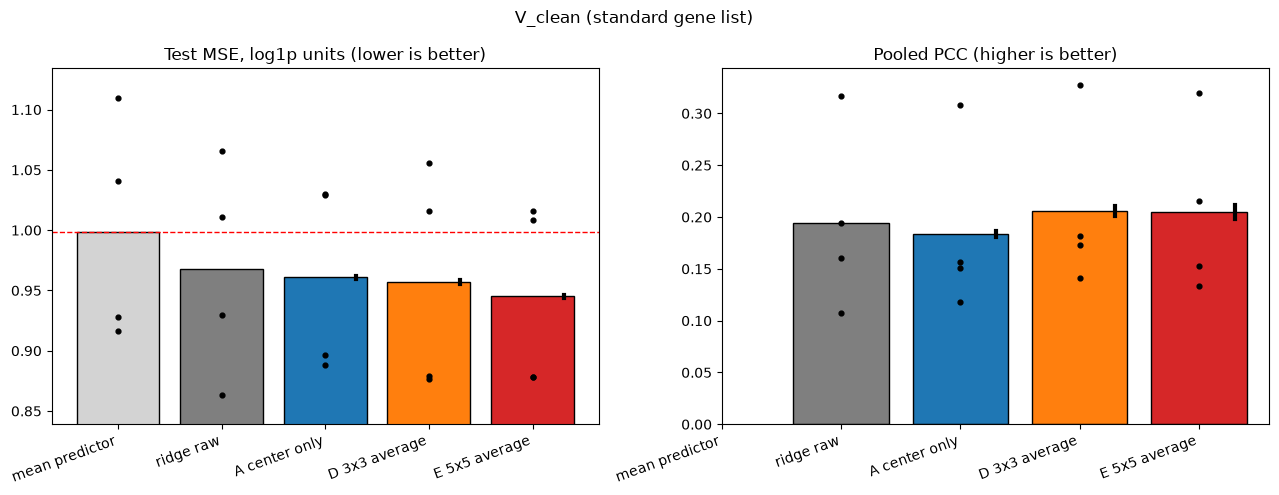

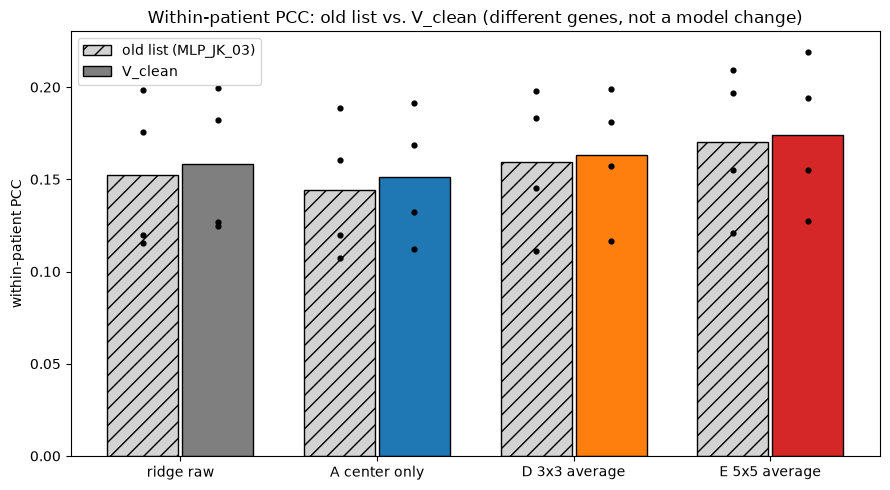

In [18]:
colors = {
    "mean predictor": "lightgrey",
    "ridge raw": "tab:gray",
    "A center only": "tab:blue",
    "D 3x3 average": "tab:orange",
    "E 5x5 average": "tab:red",
}
plot_models = list(colors)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, column, summary_column, seed_column, title in [
        (axes[0], "MSE", "test_MSE", "seed_range_test_MSE", "Test MSE, log1p units (lower is better)"),
        (axes[1], "PCC", "pooled_PCC", "seed_range_pooled_PCC", "Pooled PCC (higher is better)")]:
    for i, model_name in enumerate(plot_models):
        values = fold_scores.loc[fold_scores["model"] == model_name, column]
        if values.notna().any():
            ax.bar(i, values.mean(), color=colors[model_name], edgecolor="black")
            ax.scatter(np.full(len(values), i), values, color="black", s=12, zorder=3)
        row = summary[summary["model"] == model_name].iloc[0]
        if pd.notna(row.get(seed_column)):
            half = row[seed_column] / 2
            ax.plot([i + 0.3, i + 0.3], [row[summary_column] - half, row[summary_column] + half], color="black", linewidth=3)
    ax.set_xticks(range(len(plot_models)))
    ax.set_xticklabels(plot_models, rotation=20, ha="right")
    ax.set_title(title)
mean_mse = summary.loc[summary["model"] == "mean predictor", "test_MSE"].iloc[0]
axes[0].axhline(mean_mse, color="red", linestyle="--", linewidth=1)
low = fold_scores.loc[fold_scores["model"].isin(plot_models), "MSE"].min()
high = fold_scores.loc[fold_scores["model"].isin(plot_models), "MSE"].max()
axes[0].set_ylim(low - 0.1 * (high - low), high + 0.1 * (high - low))
fig.suptitle("V_clean (standard gene list)")
plt.tight_layout()
save_figure("1_mse_and_pcc.png")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
within_models = [m for m in plot_models if m != "mean predictor"]
width = 0.38
for i, model_name in enumerate(within_models):
    for j, (label, table, color) in enumerate([("old list (MLP_JK_03)", old_fold_scores, "lightgrey"),
                                               ("V_clean", fold_scores, colors[model_name])]):
        values = table.loc[table["model"] == model_name, "PCC_within"]
        x = i + (j - 0.5) * width
        ax.bar(x, values.mean(), width * 0.95, color=color, edgecolor="black",
               label=label if i == 0 else None, hatch="//" if j == 0 else None)
        ax.scatter(np.full(len(values), x), values, color="black", s=12, zorder=3)
ax.set_xticks(range(len(within_models)))
ax.set_xticklabels(within_models)
ax.set_ylabel("within-patient PCC")
ax.set_title("Within-patient PCC: old list vs. V_clean (different genes, not a model change)")
ax.legend()
plt.tight_layout()
save_figure("2_within_old_vs_new.png")
plt.show()

## Step 13. Save results and add them to the log

`all_results.csv` gets a `gene_list` column. Earlier rows are filled in: `old_top50` (the old list, MLP_JK_01–07), `G_norm` (MLP_JK_07's NORM gene list), `pool_500` (MLP_JK_08; its condition names S, V or R). This notebook's rows get `V_clean`. If this notebook is run again, its old rows are replaced instead of duplicated.

In [19]:
summary.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False)
fold_scores.to_csv(os.path.join(OUT_DIR, "fold_scores.csv"), index=False)
old_vs_new.to_csv(os.path.join(OUT_DIR, "old_vs_new.csv"), index=False)
best_check.to_csv(os.path.join(OUT_DIR, "best_check.csv"), index=False)
pooled.to_csv(os.path.join(OUT_DIR, "pooled_gene_scores.csv"), index=False)
within.to_csv(os.path.join(OUT_DIR, "within_patient_gene_scores.csv"), index=False)
val_scores.to_csv(os.path.join(OUT_DIR, "validation_scores.csv"), index=False)
chosen_settings.to_csv(os.path.join(OUT_DIR, "chosen_settings.csv"), index=False)
with open(os.path.join(OUT_DIR, "rankings.txt"), "w") as f:
    for title, text in rankings.items():
        f.write(f"{title}:\n  {text}\n")

settings = {
    "notebook": NOTEBOOK_NAME,
    "gene_list": GENE_LIST,
    "standard_gene_rule": standard_gene_rule,
    "model_names": MODEL_NAMES,
    "neighbor_distance": NEIGHBOR_DISTANCE,
    "n_pcs": N_PCS,
    "n_folds": N_FOLDS,
    "n_inner_folds": N_INNER_FOLDS,
    "alphas": [float(a) for a in ALPHAS],
    "min_test_sd": MIN_TEST_SD,
    "seed": SEED,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "weight_decay": WEIGHT_DECAY,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "shrink_factors": SHRINK_FACTORS,
    "n_val_groups": N_VAL_GROUPS,
    "n_final_seeds": N_FINAL_SEEDS,
    "device": str(device),
    "torch_version": torch.__version__,
}
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2)

if LOG_RESULTS:
    today = datetime.date.today().isoformat()
    log_rows = []
    for _, row in summary.iterrows():
        log_rows.append({
            "notebook": NOTEBOOK_NAME,
            "condition": row["model"],
            "pooled_PCC": row["pooled_PCC"],
            "within_patient_PCC": row["within_PCC"],
            "NRMSE": row["NRMSE"],
            "mean_predictor_NRMSE": mean_predictor_nrmse,
            "val_PCC": row.get("val_PCC", np.nan),
            "val_NRMSE": row.get("val_NRMSE", np.nan),
            "date": today,
            "target": "raw",
            "gene_list": GENE_LIST,
        })
    new_rows = pd.DataFrame(log_rows)
    old_log = pd.read_csv(RESULTS_LOG)
    if "gene_list" not in old_log.columns:
        old_log["gene_list"] = np.nan
    missing = old_log["gene_list"].isna()
    is_pool = old_log["notebook"] == "MLP_JK_08"
    is_g_norm = (old_log["notebook"] == "MLP_JK_07") & old_log["condition"].str.contains("G_norm")
    old_log.loc[missing & is_pool, "gene_list"] = "pool_500"
    old_log.loc[missing & is_g_norm, "gene_list"] = "G_norm"
    old_log.loc[missing & ~is_pool & ~is_g_norm, "gene_list"] = "old_top50"
    old_log = old_log[old_log["notebook"] != NOTEBOOK_NAME]
    new_log = pd.concat([old_log, new_rows], ignore_index=True)
    new_log.to_csv(RESULTS_LOG, index=False)
    print(new_log["gene_list"].value_counts().to_string())
    print(new_log.tail(6).round(4).to_string(index=False))

print("\nSaved to", OUT_DIR)
for name in sorted(os.listdir(OUT_DIR)):
    print("  ", name)

gene_list
old_top50    43
pool_500      6
V_clean       6
G_norm        5
 notebook                   condition  pooled_PCC  within_patient_PCC  NRMSE  mean_predictor_NRMSE  val_PCC  val_NRMSE       date target gene_list
MLP_JK_09              mean predictor         NaN                 NaN 1.0980                 1.098      NaN        NaN 2026-11-19    raw   V_clean
MLP_JK_09                   ridge raw      0.1945              0.1573 1.0863                 1.098      NaN        NaN 2026-11-19    raw   V_clean
MLP_JK_09               A center only      0.1835              0.1503 1.0776                 1.098   0.1915     1.0923 2026-11-19    raw   V_clean
MLP_JK_09               D 3x3 average      0.2059              0.1626 1.0755                 1.098   0.2078     1.0883 2026-11-19    raw   V_clean
MLP_JK_09               E 5x5 average      0.2053              0.1731 1.0673                 1.098   0.2376     1.0804 2026-11-19    raw   V_clean
MLP_JK_09 O ORACLE (uses test labels)      0

/var/folders/_1/217dtc150_g1p0nhm5lgll4h0000gn/T/ipykernel_60023/3310262384.py:65: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'pool_500' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  old_log.loc[missing & is_pool, "gene_list"] = "pool_500"


## Summary in plain words: the new reference numbers on V_clean

**What changed in the gene list:** V_clean keeps 46–48 of the old 50 genes per fold. **Every gene that left was an `__ambiguous` bin** (2–4 per fold); the 10% detection rule removed nothing else. The genes that came in are the next most variable real genes (EEF2, RPL8, CTSD, LY6E, P4HB, RPL18, ACTG1, FN1, RPS4X, XBP1, HLA-B, IGFBP2, RPL31, depending on the fold). V_clean equals MLP_JK_08's V in every fold. The rule is saved in `results/standard_gene_rule.json` and the lists in `standard_genes.csv`.

### What each score means

| Score | What it means | Good vs. bad |
|---|---|---|
| **Test MSE** (the loss) | Average squared difference between predicted and true log1p expression | Lower is better; mean predictor = 0.999 |
| **Pooled PCC** | Correlation between predicted and true expression over all test spots | Higher is better; 0 = no relation |
| **Within-patient PCC** | The same correlation inside one patient at a time | Higher is better |
| **NRMSE** | Error ÷ the gene's spread | Lower is better; below the mean predictor (1.098) = better than guessing |
| **Validation PCC / NRMSE** | The same scores on held-out *training* patients; the only scores used for choosing | Higher PCC, lower NRMSE |
| **Level share** | Fraction of the MSE that comes from whole slides being shifted (MLP_JK_06) | Lower = less slide-level error |

### The new reference numbers (V_clean, test patients, 4 folds)

| Model | Test MSE | Pooled PCC | Within-patient PCC | NRMSE | Validation PCC | Validation NRMSE | k | Level share |
|---|---|---|---|---|---|---|---|---|
| mean predictor | 0.9987 | – | – | 1.0980 | – | – | – | 59.3% |
| ridge raw | 0.9674 | 0.1945 | 0.1573 | 1.0863 | – | – | – | 57.0% |
| A center only | 0.9609 | 0.1835 | 0.1503 | 1.0776 | 0.1915 | 1.0923 | 0.4 | 58.7% |
| D center + 3×3 | 0.9568 | **0.2059** | 0.1626 | 1.0755 | 0.2078 | 1.0883 | 0.4 (0.2 in fold 1) | 58.9% |
| **E center + 5×5** | **0.9451** | 0.2053 | **0.1731** | **1.0673** | **0.2376** | **1.0804** | 0.4 | 58.7% |
| O ORACLE (uses test labels) | 0.3937 | 0.6609 | 0.2548 | 0.7230 | – | – | – | 0% |

Seed spread (MLPs): test MSE ≤ 0.0034, pooled PCC ≤ 0.014, within-patient PCC ≤ 0.010. Level + pattern error add up to the MSE for every model and fold. As before, about 59% of the error is slide-level.

### Rankings, old list vs. V_clean

**Test MSE (lower is better)**
- Old list: D 0.9584 < E 0.9589 < A 0.9728 < ridge 0.9837 < mean 1.0092
- V_clean: **E 0.9451** < D 0.9568 < A 0.9609 < ridge 0.9674 < mean 0.9987

**Validation PCC (higher is better)**
- Old list: E 0.2256 > D 0.2076 > A 0.1898
- V_clean: **E 0.2376** > D 0.2078 > A 0.1915

- **The ranking is the same as before**, with one small change: D and E swap places on test MSE. On the old list they were tied (0.0005 apart). On V_clean, E is ahead by 0.012, lower in 3 of 4 folds and well above the seed spread. Every MLP beats ridge, which beats the mean predictor, and A is the weakest MLP.
- **Validation PCC keeps the same order** (E > D > A), with E's lead a bit larger.
- **The numbers moved only slightly**, because only 2–4 genes per fold changed. Old and new numbers are on **different genes**, so the differences are not model improvements (`old_vs_new.csv`, Figure 2).

### Best model on V_clean

By the usual rule (highest validation PCC, validation NRMSE no worse than the mean predictor's), **E (center + 5×5 average) is Best on V_clean**, with validation PCC 0.2376 and validation NRMSE 1.0804 vs. 1.1128 for the mean predictor. That's the same setup as the current MLP_JK_Best. **MLP_JK_Best was not changed**; it still holds E's numbers on the old list (validation PCC 0.2256). Rebuilding it on V_clean would only update its reference numbers, not the model.

### Use from now on

The reference numbers to beat on V_clean are **E: test MSE 0.945, pooled PCC 0.205, within-patient PCC 0.173, validation PCC 0.238**. The baselines are ridge (MSE 0.967, PCC 0.195) and the mean predictor (MSE 0.999, NRMSE 1.098).